# Image Preprocessing and Facial Recognition

## Purpose

This notebook processes facial images for the multimodal authentication and
product recommendation system.

The image pipeline will:

1. Validate the facial-image collection.
2. Display sample images for each authorized member.
3. Apply image preprocessing and augmentation.
4. Extract facial features.
5. Train and evaluate a facial recognition model.
6. Test whether unauthorized faces are correctly rejected.

## Dataset roles

- `member01`, `member02`, `member03`, and `member04` are authorized identities.
- `unauthorized_validation` is used during rejection-threshold development.
- `unauthorized_test` remains unseen until final evaluation.

Each identity currently provides neutral, smiling, and surprised expressions.

In [51]:
from google.colab import drive
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import random
import torch

drive.mount("/content/drive")

# Define project paths
MY_DRIVE = Path("/content/drive/MyDrive")
PROJECT_ROOT = MY_DRIVE / "formative-2-machine-learning-pipeline"
IMAGE_ROOT = PROJECT_ROOT / "data" / "images"

# Validate paths
assert PROJECT_ROOT.exists(), f"Project folder not found: {PROJECT_ROOT}"
assert IMAGE_ROOT.exists(), f"Image folder not found: {IMAGE_ROOT}"

print("Project root:", PROJECT_ROOT)
print("Image root:", IMAGE_ROOT)
print("\nImage collection folders:")

for folder in sorted(IMAGE_ROOT.iterdir()):
    if folder.is_dir():
        print("-", folder.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/formative-2-machine-learning-pipeline
Image root: /content/drive/MyDrive/formative-2-machine-learning-pipeline/data/images

Image collection folders:
- member01
- member02
- member03
- member04
- unauthorized_test
- unauthorized_validation


In [52]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

In [7]:
identity_roles = {
    "member01": "authorized",
    "member02": "authorized",
    "member03": "authorized",
    "member04": "authorized",
    "unauthorized_validation": "unauthorized validation",
    "unauthorized_test": "unauthorized final test",
}

required_expressions = ["neutral", "smile", "surprised"]
allowed_extensions = {".jpg", ".jpeg", ".png"}

collection_rows = []

for identity, role in identity_roles.items():
    identity_folder = IMAGE_ROOT / identity

    image_files = []
    if identity_folder.exists():
        image_files = [
            path
            for path in sorted(identity_folder.iterdir())
            if path.is_file() and path.suffix.lower() in allowed_extensions
        ]

    available_stems = {path.stem.lower() for path in image_files}

    row = {
        "identity": identity,
        "role": role,
        "folder_exists": identity_folder.exists(),
        "image_count": len(image_files),
    }

    for expression in required_expressions:
        expected_stem = f"{identity}_{expression}_01"
        row[expression] = expected_stem in available_stems

    collection_rows.append(row)

collection_summary = pd.DataFrame(collection_rows)
collection_summary

,identity,role,folder_exists,image_count,neutral,smile,surprised
0,member01,authorized,True,3,True,True,True
1,member02,authorized,True,3,True,True,True
2,member03,authorized,True,3,True,True,True
3,member04,authorized,True,3,True,True,True
4,unauthorized_validation,unauthorized validation,True,3,True,True,True
5,unauthorized_test,unauthorized final test,True,3,True,True,True


In [8]:
required_columns = ["neutral", "smile", "surprised"]

missing_items = []

for _, row in collection_summary.iterrows():
    if not row["folder_exists"]:
        missing_items.append(f"{row['identity']}: folder is missing")
        continue

    for expression in required_columns:
        if not row[expression]:
            missing_items.append(
                f"{row['identity']}: missing or incorrectly named {expression} image"
            )

if missing_items:
    print("Collection problems found:")
    for problem in missing_items:
        print("-", problem)
else:
    print("Collection validation passed.")
    print("All current identities have the three required expressions.")

Collection validation passed.
All current identities have the three required expressions.


## Authorized Image Visualization and Quality Review

The following grid displays the neutral, smiling, and surprised images for each
authorized member. This visual inspection checks whether the faces are clear,
correctly labeled, sufficiently visible, and suitable for preprocessing.

The unauthorized test identity is intentionally excluded and reserved for the
final evaluation.

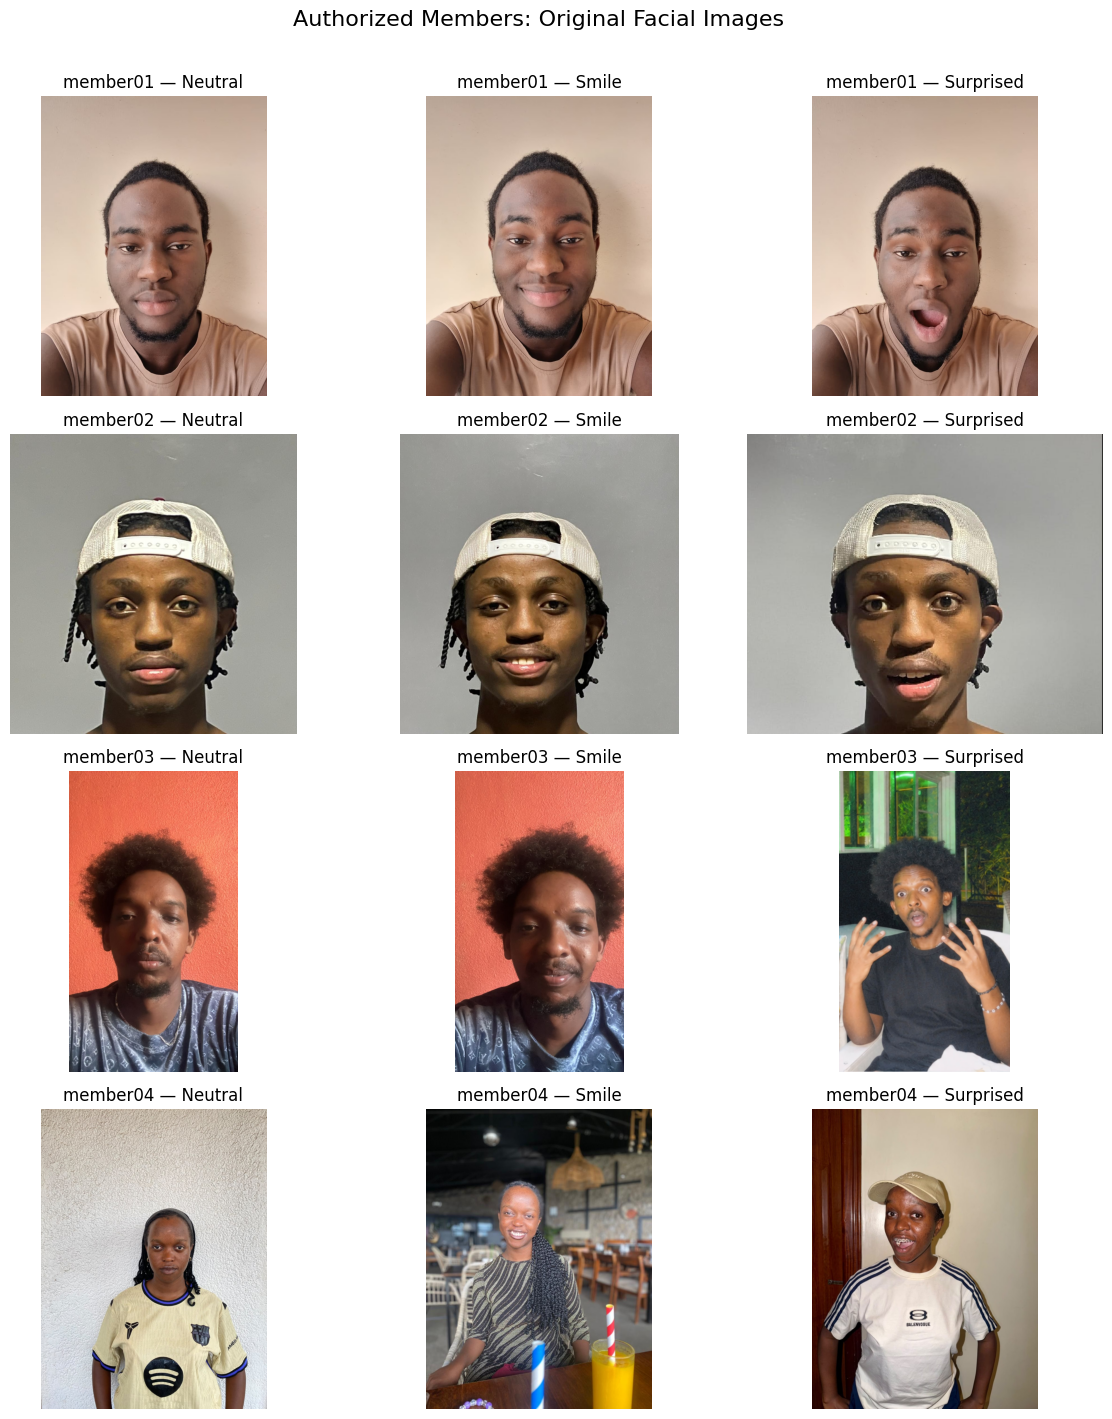

In [9]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

authorized_members = [
    "member01",
    "member02",
    "member03",
    "member04",
]

expressions = [
    "neutral",
    "smile",
    "surprised",
]

fig, axes = plt.subplots(
    nrows=len(authorized_members),
    ncols=len(expressions),
    figsize=(12, 14),
)

for row_index, member_id in enumerate(authorized_members):
    member_folder = IMAGE_ROOT / member_id

    for column_index, expression in enumerate(expressions):
        expected_stem = f"{member_id}_{expression}_01"

        matching_files = [
            path
            for path in member_folder.iterdir()
            if path.is_file()
            and path.suffix.lower() in allowed_extensions
            and path.stem.lower() == expected_stem
        ]

        if len(matching_files) != 1:
            raise ValueError(
                f"Expected one file for {expected_stem}, "
                f"but found {len(matching_files)}."
            )

        image_path = matching_files[0]

        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            axes[row_index, column_index].imshow(image)

        axes[row_index, column_index].set_title(
            f"{member_id} — {expression.capitalize()}"
        )
        axes[row_index, column_index].axis("off")

plt.suptitle(
    "Authorized Members: Original Facial Images",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()
plt.show()

## Face Detection

Before augmentation and feature extraction, MTCNN is used to verify that one
face can be detected in every authorized image.

Face detection allows the pipeline to isolate the facial region and reduce the
influence of backgrounds, clothing, and other irrelevant image content.
Detection confidence and bounding boxes will be reviewed before continuing.

In [13]:
!pip install -q --no-deps facenet-pytorch==2.6.0

In [14]:
import torch
from facenet_pytorch import MTCNN

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("MTCNN imported successfully.")

CUDA available: True
GPU: Tesla T4
MTCNN imported successfully.


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

face_detector = MTCNN(
    image_size=160,
    margin=20,
    keep_all=True,
    post_process=True,
    device=device,
)

print("Processing device:", device)
print("MTCNN initialized successfully.")

Processing device: cuda
MTCNN initialized successfully.


### Face Detection on Authorized Images

MTCNN is applied to every original authorized image. The visualization displays
the detected face bounding box and confidence score.

A suitable image should contain exactly one detected face with high confidence.
Images with no detection, multiple detections, or low confidence will be reviewed
before augmentation.

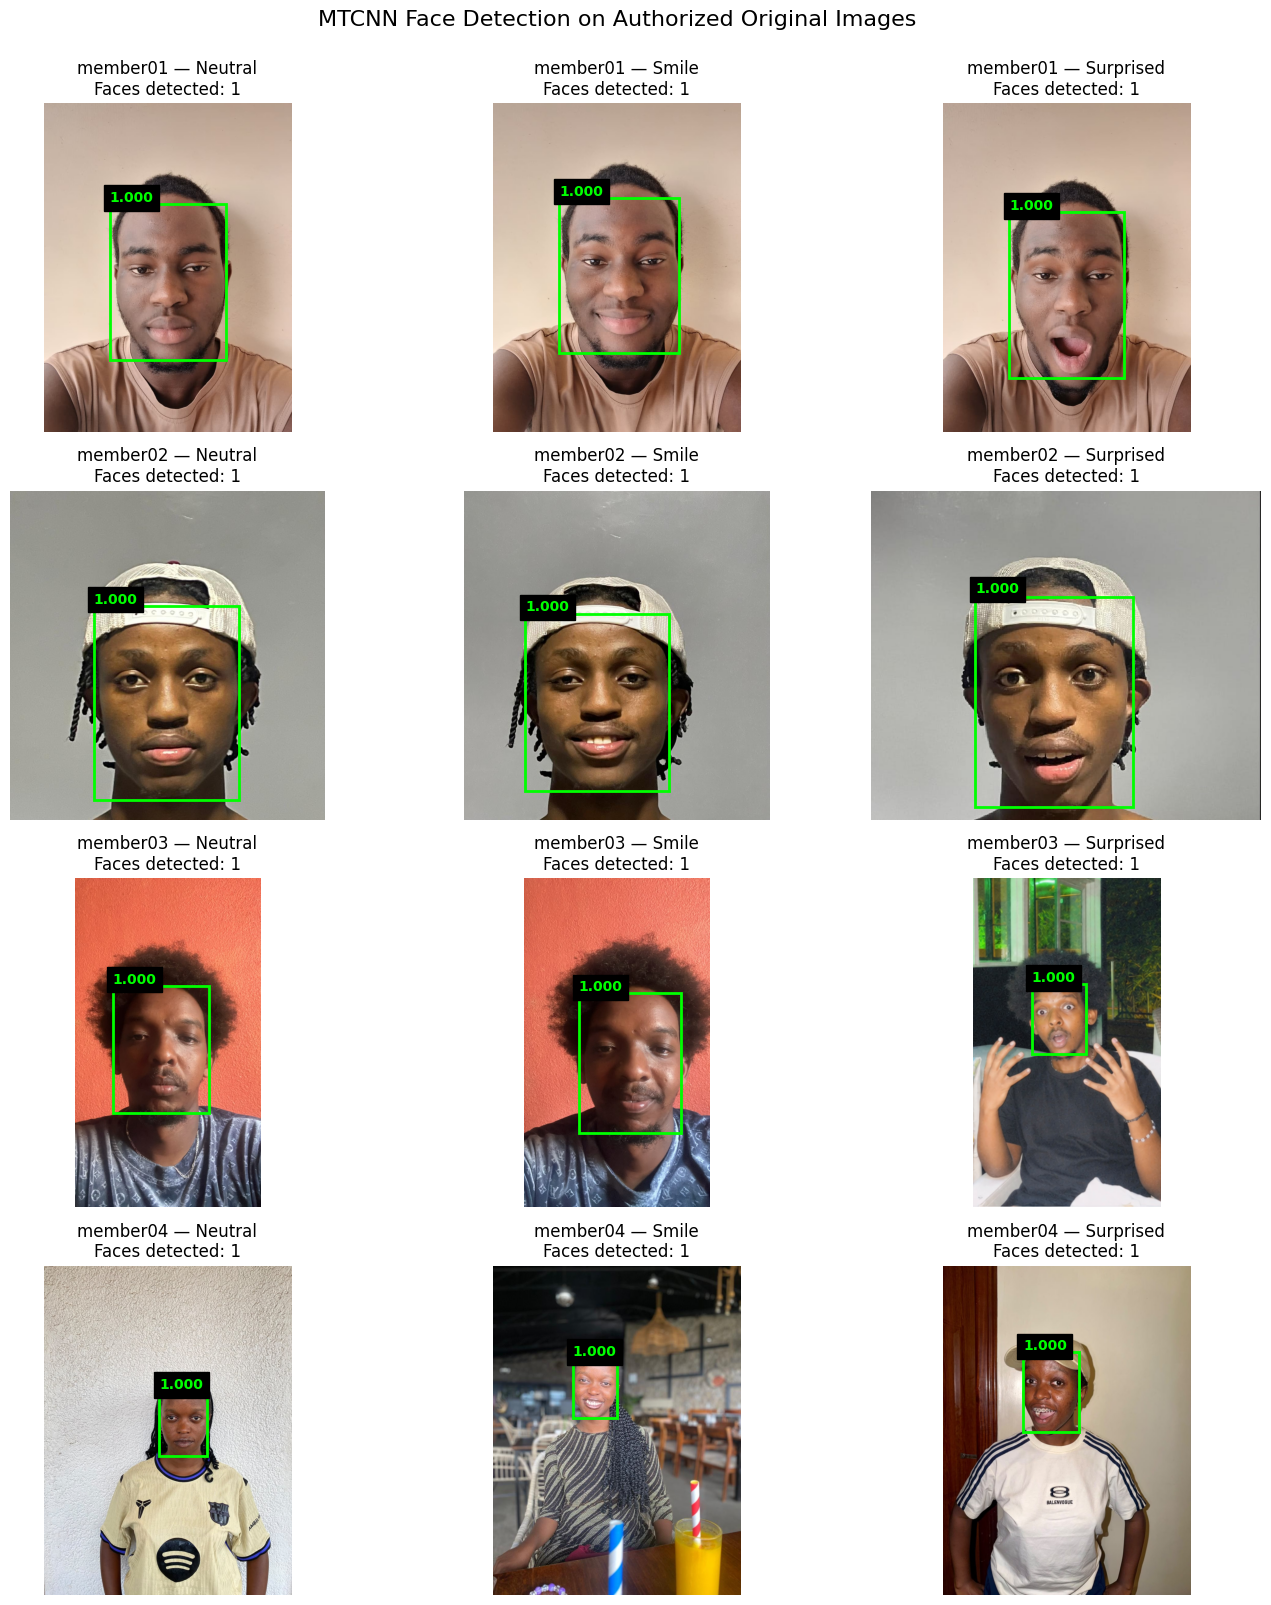

,member_id,expression,source_file,faces_detected,highest_confidence
0,member01,neutral,member01_neutral_01.jpeg,1,0.999998
1,member01,smile,member01_smile_01.jpeg,1,0.999921
2,member01,surprised,member01_surprised_01.jpeg,1,0.999691
3,member02,neutral,member02_neutral_01.jpeg,1,0.999994
4,member02,smile,member02_smile_01.jpeg,1,1.000000
5,member02,surprised,member02_surprised_01.jpeg,1,0.999969
6,member03,neutral,member03_neutral_01.jpeg,1,0.999971
7,member03,smile,member03_smile_01.jpeg,1,0.999931
8,member03,surprised,member03_surprised_01.jpeg,1,0.999985
9,member04,neutral,member04_neutral_01.jpeg,1,0.999916


Figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/authorized_face_detection.png


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps

authorized_members = [
    "member01",
    "member02",
    "member03",
    "member04",
]

expressions = [
    "neutral",
    "smile",
    "surprised",
]

detection_results = []

fig, axes = plt.subplots(
    nrows=len(authorized_members),
    ncols=len(expressions),
    figsize=(14, 16),
)

for row_index, member_id in enumerate(authorized_members):
    member_folder = IMAGE_ROOT / member_id

    for column_index, expression in enumerate(expressions):
        axis = axes[row_index, column_index]
        expected_stem = f"{member_id}_{expression}_01"

        matching_files = [
            path
            for path in member_folder.iterdir()
            if path.is_file()
            and path.suffix.lower() in allowed_extensions
            and path.stem.lower() == expected_stem
        ]

        if len(matching_files) != 1:
            raise ValueError(
                f"Expected one file for {expected_stem}, "
                f"but found {len(matching_files)}."
            )

        image_path = matching_files[0]

        with Image.open(image_path) as opened_image:
            image = ImageOps.exif_transpose(opened_image).convert("RGB")

        boxes, probabilities = face_detector.detect(image)

        face_count = 0 if boxes is None else len(boxes)
        highest_confidence = None

        axis.imshow(image)

        if boxes is not None and probabilities is not None:
            valid_probabilities = [
                float(probability)
                for probability in probabilities
                if probability is not None
            ]

            if valid_probabilities:
                highest_confidence = max(valid_probabilities)

            for box, probability in zip(boxes, probabilities):
                x1, y1, x2, y2 = box

                rectangle = Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    fill=False,
                    color="lime",
                    linewidth=2,
                )
                axis.add_patch(rectangle)

                if probability is not None:
                    axis.text(
                        x1,
                        max(0, y1 - 8),
                        f"{probability:.3f}",
                        color="lime",
                        fontsize=10,
                        fontweight="bold",
                        backgroundcolor="black",
                    )

        detection_results.append(
            {
                "member_id": member_id,
                "expression": expression,
                "source_file": image_path.name,
                "faces_detected": face_count,
                "highest_confidence": highest_confidence,
            }
        )

        axis.set_title(
            f"{member_id} — {expression.capitalize()}\n"
            f"Faces detected: {face_count}"
        )
        axis.axis("off")

plt.suptitle(
    "MTCNN Face Detection on Authorized Original Images",
    fontsize=16,
    y=1.0,
)
plt.tight_layout()

figure_directory = PROJECT_ROOT / "outputs" / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)

detection_figure_path = (
    figure_directory / "authorized_face_detection.png"
)
plt.savefig(
    detection_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

detection_summary = pd.DataFrame(detection_results)
display(detection_summary)

print("Figure saved to:", detection_figure_path)

### Face Detection Findings

MTCNN successfully detected exactly one face in all 12 authorized original
images. Every detection confidence exceeded 0.999, and visual inspection
confirmed that each bounding box surrounded the correct face.

The detector performed successfully despite differences in lighting,
background, distance, clothing, and headwear. Therefore, all authorized images
are retained for preprocessing. The detected faces will now be aligned, cropped,
and resized to 160 × 160 pixels before augmentation and feature extraction.

## Face Alignment, Cropping, and Resizing

MTCNN is used to align and crop each detected face. Every processed face is
resized to 160 × 160 pixels, which is the input size expected by the selected
FaceNet embedding model.

The original images remain unchanged. Processed face crops are stored separately
for visualization, augmentation, and feature extraction.

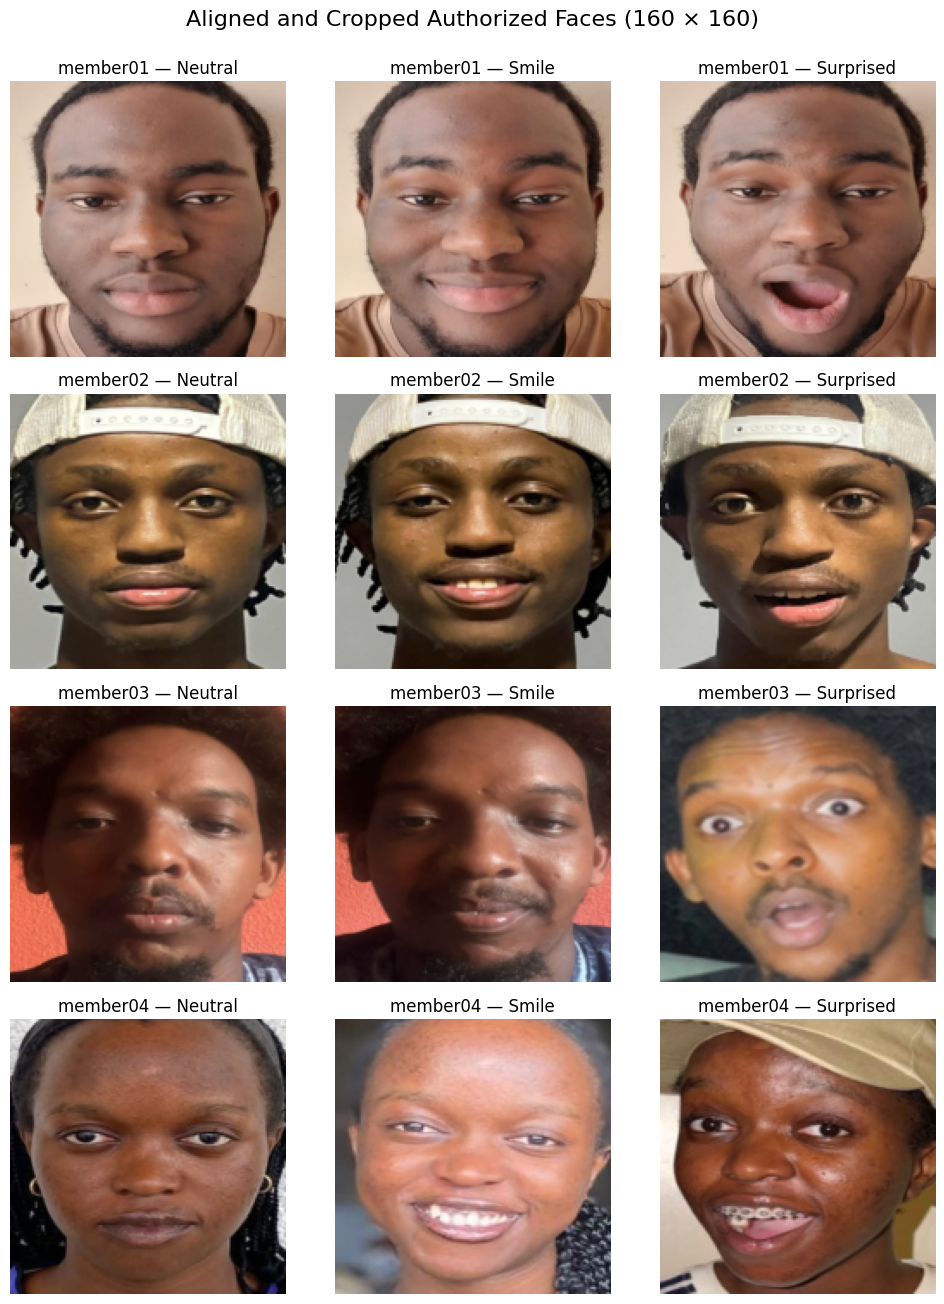

,member_id,expression,source_file,aligned_file,width,height
0,member01,neutral,member01_neutral_01.jpeg,member01_neutral_01_aligned.png,160,160
1,member01,smile,member01_smile_01.jpeg,member01_smile_01_aligned.png,160,160
2,member01,surprised,member01_surprised_01.jpeg,member01_surprised_01_aligned.png,160,160
3,member02,neutral,member02_neutral_01.jpeg,member02_neutral_01_aligned.png,160,160
4,member02,smile,member02_smile_01.jpeg,member02_smile_01_aligned.png,160,160
5,member02,surprised,member02_surprised_01.jpeg,member02_surprised_01_aligned.png,160,160
6,member03,neutral,member03_neutral_01.jpeg,member03_neutral_01_aligned.png,160,160
7,member03,smile,member03_smile_01.jpeg,member03_smile_01_aligned.png,160,160
8,member03,surprised,member03_surprised_01.jpeg,member03_surprised_01_aligned.png,160,160
9,member04,neutral,member04_neutral_01.jpeg,member04_neutral_01_aligned.png,160,160


Aligned face directory: /content/drive/MyDrive/formative-2-machine-learning-pipeline/data/processed/images/aligned
Figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/authorized_aligned_faces.png


In [17]:
import numpy as np

aligned_root = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "images"
    / "aligned"
)
aligned_root.mkdir(parents=True, exist_ok=True)

aligned_records = []
aligned_face_cache = {}

fig, axes = plt.subplots(
    nrows=len(authorized_members),
    ncols=len(expressions),
    figsize=(10, 13),
)

for row_index, member_id in enumerate(authorized_members):
    member_folder = IMAGE_ROOT / member_id
    member_output_folder = aligned_root / member_id
    member_output_folder.mkdir(parents=True, exist_ok=True)

    for column_index, expression in enumerate(expressions):
        expected_stem = f"{member_id}_{expression}_01"

        matching_files = [
            path
            for path in member_folder.iterdir()
            if path.is_file()
            and path.suffix.lower() in allowed_extensions
            and path.stem.lower() == expected_stem
        ]

        if len(matching_files) != 1:
            raise ValueError(
                f"Expected one file for {expected_stem}, "
                f"but found {len(matching_files)}."
            )

        source_path = matching_files[0]

        with Image.open(source_path) as opened_image:
            original_image = ImageOps.exif_transpose(
                opened_image
            ).convert("RGB")

        face_batch = face_detector(original_image)

        if face_batch is None:
            raise ValueError(
                f"No face detected while processing {source_path.name}."
            )

        if face_batch.shape[0] != 1:
            raise ValueError(
                f"Expected one face in {source_path.name}, "
                f"but received {face_batch.shape[0]}."
            )

        face_tensor = face_batch[0].detach().cpu()

        # Reverse MTCNN's standardization for display and image saving.
        face_array = face_tensor.permute(1, 2, 0).numpy()
        face_array = np.clip(
            face_array * 128.0 + 127.5,
            0,
            255,
        ).astype(np.uint8)

        aligned_image = Image.fromarray(face_array)

        output_name = f"{expected_stem}_aligned.png"
        output_path = member_output_folder / output_name
        aligned_image.save(output_path)

        aligned_face_cache[expected_stem] = aligned_image.copy()

        aligned_records.append(
            {
                "member_id": member_id,
                "expression": expression,
                "source_file": source_path.name,
                "aligned_file": output_path.name,
                "width": aligned_image.width,
                "height": aligned_image.height,
            }
        )

        axis = axes[row_index, column_index]
        axis.imshow(aligned_image)
        axis.set_title(
            f"{member_id} — {expression.capitalize()}"
        )
        axis.axis("off")

plt.suptitle(
    "Aligned and Cropped Authorized Faces (160 × 160)",
    fontsize=16,
    y=1.0,
)
plt.tight_layout()

aligned_figure_path = (
    figure_directory / "authorized_aligned_faces.png"
)
plt.savefig(
    aligned_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

aligned_summary = pd.DataFrame(aligned_records)
display(aligned_summary)

print("Aligned face directory:", aligned_root)
print("Figure saved to:", aligned_figure_path)

### Alignment and Cropping Findings

All 12 authorized faces were successfully aligned, cropped, and resized to
160 × 160 pixels. Visual inspection confirmed that the main facial features
were retained and that no incorrect faces or background people were included.

Cropping reduced differences in background and body positioning while preserving
natural variation in expression, lighting, headwear, and face angle. The aligned
images are suitable for augmentation and facial-feature extraction.

## Image Augmentation

Three deterministic augmentations are applied to every aligned authorized face:

1. Horizontal flipping introduces left-right variation.
2. A small eight-degree rotation introduces minor head-angle variation.
3. A slight brightness increase introduces lighting variation.

The aligned original is also retained. Augmented images derived from the same
source photograph will later be grouped together during model evaluation to
prevent data leakage.

In [19]:
from PIL import ImageEnhance

augmented_root = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "images"
    / "augmented"
)
augmented_root.mkdir(parents=True, exist_ok=True)

augmentation_records = []

for record in aligned_summary.to_dict("records"):
    member_id = record["member_id"]
    expression = record["expression"]
    source_file = record["source_file"]
    aligned_file = record["aligned_file"]

    aligned_path = (
        aligned_root
        / member_id
        / aligned_file
    )

    with Image.open(aligned_path) as opened_image:
        aligned_image = opened_image.convert("RGB").copy()

    rotation_fill = aligned_image.getpixel((0, 0))

    variants = {
        "original": aligned_image,
        "horizontal_flip": ImageOps.mirror(aligned_image),
        "rotation_8deg": aligned_image.rotate(
            8,
            resample=Image.Resampling.BICUBIC,
            expand=False,
            fillcolor=rotation_fill,
        ),
        "brightness_115": ImageEnhance.Brightness(
            aligned_image
        ).enhance(1.15),
    }

    member_output_folder = augmented_root / member_id
    member_output_folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    source_stem = Path(source_file).stem

    for augmentation_name, augmented_image in variants.items():
        output_name = (
            f"{source_stem}_{augmentation_name}.png"
        )
        output_path = member_output_folder / output_name

        augmented_image.save(output_path)

        augmentation_records.append(
            {
                "member_id": member_id,
                "expression": expression,
                "source_file": source_file,
                "augmentation": augmentation_name,
                "augmented_file": output_name,
                "width": augmented_image.width,
                "height": augmented_image.height,
            }
        )

augmentation_summary = pd.DataFrame(
    augmentation_records
)

manifest_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "augmentation_manifest.csv"
)
augmentation_summary.to_csv(
    manifest_path,
    index=False,
)

display(
    pd.crosstab(
        augmentation_summary["member_id"],
        augmentation_summary["augmentation"],
    )
)

print("Total processed variants:", len(augmentation_summary))
print("Augmentation directory:", augmented_root)
print("Manifest saved to:", manifest_path)

augmentation,brightness_115,horizontal_flip,original,rotation_8deg
member_id,,,,
member01,3,3,3,3
member02,3,3,3,3
member03,3,3,3,3
member04,3,3,3,3


Total processed variants: 48
Augmentation directory: /content/drive/MyDrive/formative-2-machine-learning-pipeline/data/processed/images/augmented
Manifest saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/data/processed/augmentation_manifest.csv


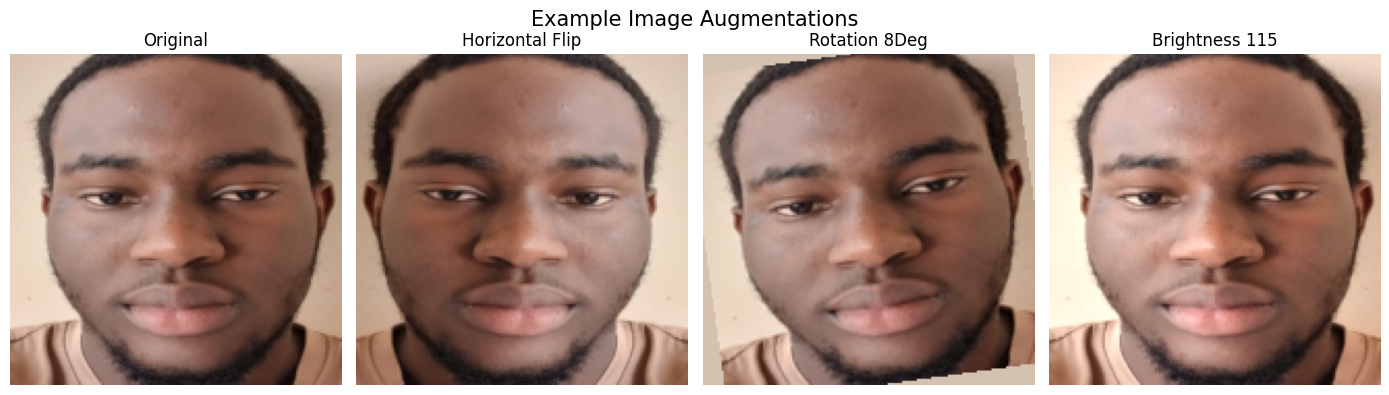

Figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/image_augmentation_examples.png


In [20]:
sample_member = "member01"
sample_expression = "neutral"
sample_source_stem = (
    f"{sample_member}_{sample_expression}_01"
)

sample_augmentations = [
    "original",
    "horizontal_flip",
    "rotation_8deg",
    "brightness_115",
]

fig, axes = plt.subplots(
    1,
    len(sample_augmentations),
    figsize=(14, 4),
)

for axis, augmentation_name in zip(
    axes,
    sample_augmentations,
):
    image_path = (
        augmented_root
        / sample_member
        / f"{sample_source_stem}_{augmentation_name}.png"
    )

    with Image.open(image_path) as opened_image:
        image = opened_image.convert("RGB")
        axis.imshow(image)

    axis.set_title(
        augmentation_name.replace("_", " ").title()
    )
    axis.axis("off")

plt.suptitle(
    "Example Image Augmentations",
    fontsize=15,
)
plt.tight_layout()

augmentation_figure_path = (
    figure_directory
    / "image_augmentation_examples.png"
)
plt.savefig(
    augmentation_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", augmentation_figure_path)

### Augmentation Findings

Three augmentations were successfully applied to every aligned facial image:
horizontal flipping, an eight-degree rotation, and a slight brightness increase.

Together with the aligned originals, this produced 48 processed images, with
12 variants for each authorized member. Visual inspection confirmed that the
transformations preserved identity and important facial features.

These augmentations increase variation in orientation and lighting, but they do
not represent independent observations. All variants from the same source image
must remain in the same data group during model evaluation to prevent leakage.

## Facial Feature Extraction

A pretrained FaceNet InceptionResnetV1 model is used to convert every processed
face into a 512-dimensional numerical embedding.

Face embeddings represent identity-related facial characteristics in a compact
numeric format. The embeddings, together with sample metadata, are saved in
`image_features.csv` for facial-recognition model development.

Only authorized identities are included in this feature file. Unauthorized
validation and test images remain separate for rejection evaluation.

In [21]:
from facenet_pytorch import (
    InceptionResnetV1,
    fixed_image_standardization,
)

embedding_model = InceptionResnetV1(
    pretrained="vggface2"
).eval().to(device)

print("Embedding model initialized.")
print("Model device:", device)

  0%|          | 0.00/107M [00:00<?, ?B/s]

Embedding model initialized.
Model device: cuda


In [22]:
import torch.nn.functional as functional

feature_metadata = []
face_tensors = []

for record in augmentation_summary.to_dict("records"):
    member_id = record["member_id"]
    augmented_file = record["augmented_file"]

    image_path = (
        augmented_root
        / member_id
        / augmented_file
    )

    with Image.open(image_path) as opened_image:
        image = opened_image.convert("RGB")
        image_array = np.asarray(
            image,
            dtype=np.float32,
        ).copy()

    image_tensor = torch.from_numpy(
        image_array
    ).permute(2, 0, 1)

    image_tensor = fixed_image_standardization(
        image_tensor
    )

    face_tensors.append(image_tensor)

    feature_metadata.append(
        {
            "sample_id": (
                f"{Path(record['source_file']).stem}"
                f"__{record['augmentation']}"
            ),
            "member_id": member_id,
            "expression": record["expression"],
            "source_file": record["source_file"],
            "augmentation": record["augmentation"],
            "augmented_file": augmented_file,
        }
    )

face_batch = torch.stack(face_tensors).to(device)

with torch.inference_mode():
    embeddings = embedding_model(face_batch)
    embeddings = functional.normalize(
        embeddings,
        p=2,
        dim=1,
    )

embeddings_array = embeddings.cpu().numpy()

print("Input batch shape:", face_batch.shape)
print("Embedding matrix shape:", embeddings_array.shape)

Input batch shape: torch.Size([48, 3, 160, 160])
Embedding matrix shape: (48, 512)


In [23]:
metadata_table = pd.DataFrame(feature_metadata)

embedding_columns = [
    f"embedding_{index:03d}"
    for index in range(embeddings_array.shape[1])
]

embedding_table = pd.DataFrame(
    embeddings_array,
    columns=embedding_columns,
)

image_features = pd.concat(
    [
        metadata_table.reset_index(drop=True),
        embedding_table.reset_index(drop=True),
    ],
    axis=1,
)

image_features_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "image_features.csv"
)

image_features.to_csv(
    image_features_path,
    index=False,
)

print("Feature-table shape:", image_features.shape)
print("Embedding columns:", len(embedding_columns))
print("Missing feature values:", embedding_table.isna().sum().sum())
print("Saved to:", image_features_path)

display(image_features.iloc[:5, :12])

Feature-table shape: (48, 518)
Embedding columns: 512
Missing feature values: 0
Saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/data/processed/image_features.csv


,sample_id,member_id,expression,source_file,augmentation,augmented_file,embedding_000,embedding_001,embedding_002,embedding_003,embedding_004,embedding_005
0,member01_neutral_01__original,member01,neutral,member01_neutral_01.jpeg,original,member01_neutral_01_original.png,0.023805,-0.052809,-0.065982,-0.051319,0.013532,-0.094451
1,member01_neutral_01__horizontal_flip,member01,neutral,member01_neutral_01.jpeg,horizontal_flip,member01_neutral_01_horizontal_flip.png,0.023513,-0.059690,-0.060970,-0.053380,0.016868,-0.087025
2,member01_neutral_01__rotation_8deg,member01,neutral,member01_neutral_01.jpeg,rotation_8deg,member01_neutral_01_rotation_8deg.png,0.024367,-0.064443,-0.071973,-0.061080,0.039077,-0.075265
3,member01_neutral_01__brightness_115,member01,neutral,member01_neutral_01.jpeg,brightness_115,member01_neutral_01_brightness_115.png,0.021402,-0.053941,-0.064023,-0.054751,0.015045,-0.091592
4,member01_smile_01__original,member01,smile,member01_smile_01.jpeg,original,member01_smile_01_original.png,0.025833,-0.072855,-0.088824,-0.035530,0.030207,-0.075136


In [24]:
embedding_norms = np.linalg.norm(
    embeddings_array,
    axis=1,
)

feature_validation = pd.DataFrame(
    {
        "check": [
            "Feature rows",
            "Embedding dimensions",
            "Missing embedding values",
            "Minimum embedding norm",
            "Maximum embedding norm",
            "Duplicate sample IDs",
        ],
        "value": [
            len(image_features),
            len(embedding_columns),
            int(embedding_table.isna().sum().sum()),
            float(embedding_norms.min()),
            float(embedding_norms.max()),
            int(image_features["sample_id"].duplicated().sum()),
        ],
    }
)

display(feature_validation)

display(
    pd.crosstab(
        image_features["member_id"],
        image_features["augmentation"],
    )
)

,check,value
0,Feature rows,48.0
1,Embedding dimensions,512.0
2,Missing embedding values,0.0
3,Minimum embedding norm,1.0
4,Maximum embedding norm,1.0
5,Duplicate sample IDs,0.0


augmentation,brightness_115,horizontal_flip,original,rotation_8deg
member_id,,,,
member01,3,3,3,3
member02,3,3,3,3
member03,3,3,3,3
member04,3,3,3,3


### Feature Extraction Findings

The pretrained FaceNet model successfully generated 512-dimensional embeddings
for all 48 processed facial images. No feature values were missing, no sample
identifiers were duplicated, and every embedding was normalized to a magnitude
of approximately 1.0.

The feature dataset is balanced across the four authorized identities and four
image variants. The completed feature table was saved as
`data/processed/image_features.csv`.

Although the table contains augmented samples, evaluation must group records by
their original `source_file` so that related variants cannot appear across
training and testing partitions.

## Facial Embedding Similarity Analysis

Cosine similarity is used to compare the 12 original facial embeddings.

A higher similarity indicates that two facial embeddings are closer together.
Embeddings belonging to the same authorized member should generally have higher
similarity than embeddings belonging to different members.

Augmented variants are excluded from this analysis because they are derived from
the same original photographs and could produce misleadingly high similarity.

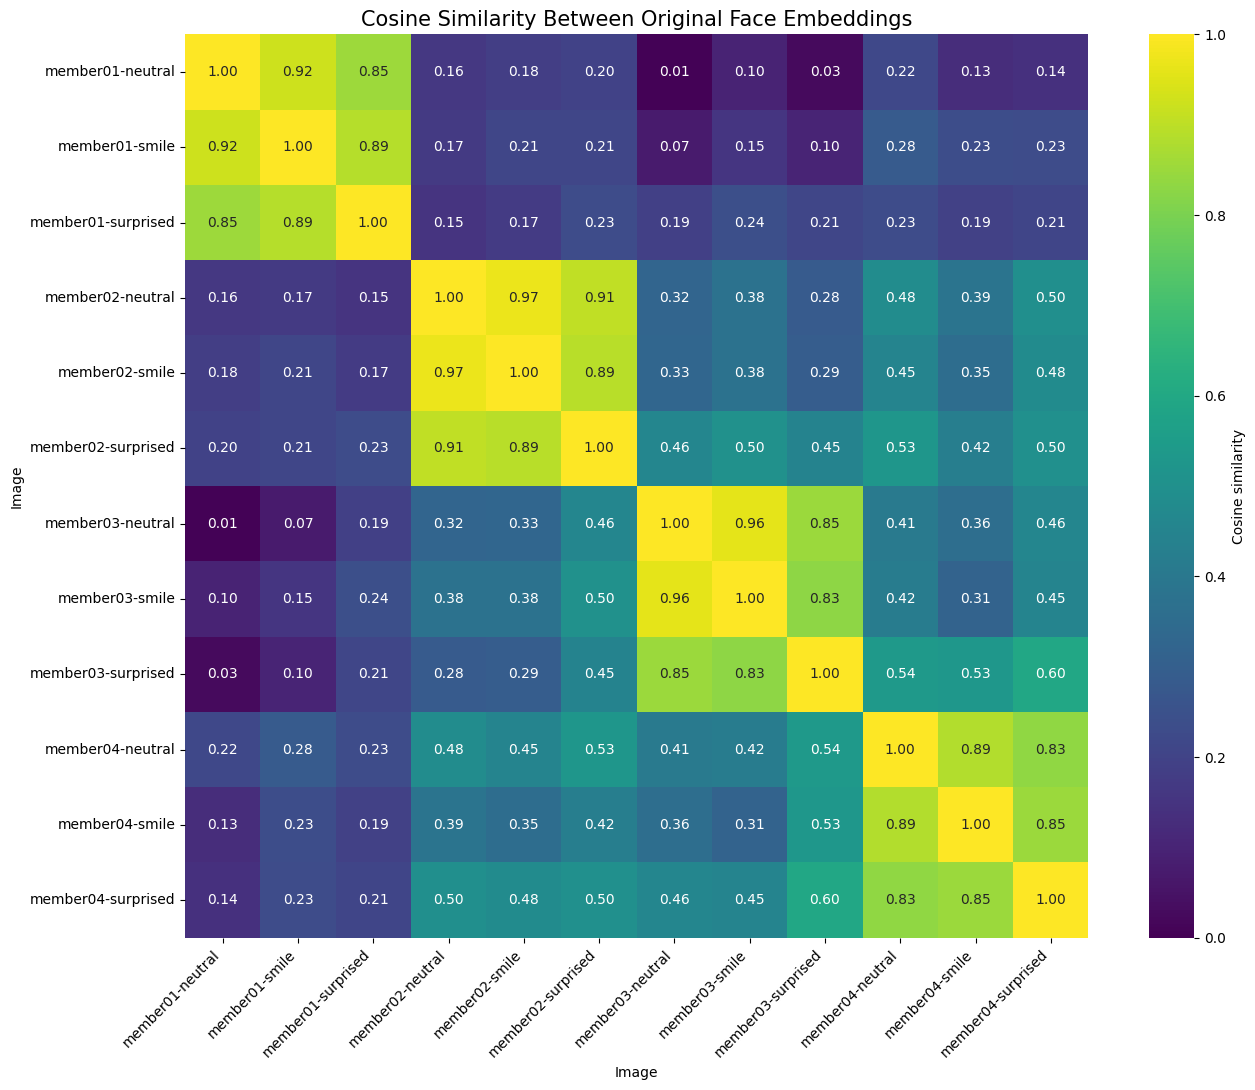

Heatmap saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/original_embedding_similarity_heatmap.png


In [25]:
import seaborn as sns

original_features = (
    image_features[
        image_features["augmentation"] == "original"
    ]
    .copy()
    .reset_index(drop=True)
)

original_embedding_matrix = original_features[
    embedding_columns
].to_numpy()

similarity_matrix = (
    original_embedding_matrix
    @ original_embedding_matrix.T
)

similarity_labels = (
    original_features["member_id"]
    + "-"
    + original_features["expression"]
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    similarity_matrix,
    xticklabels=similarity_labels,
    yticklabels=similarity_labels,
    cmap="viridis",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={
        "label": "Cosine similarity",
    },
)

plt.title(
    "Cosine Similarity Between Original Face Embeddings",
    fontsize=15,
)
plt.xlabel("Image")
plt.ylabel("Image")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

similarity_heatmap_path = (
    figure_directory
    / "original_embedding_similarity_heatmap.png"
)

plt.savefig(
    similarity_heatmap_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Heatmap saved to:", similarity_heatmap_path)

In [26]:
pairwise_records = []

for first_index in range(len(original_features)):
    for second_index in range(
        first_index + 1,
        len(original_features),
    ):
        first_member = original_features.loc[
            first_index,
            "member_id",
        ]
        second_member = original_features.loc[
            second_index,
            "member_id",
        ]

        relationship = (
            "Same identity"
            if first_member == second_member
            else "Different identities"
        )

        pairwise_records.append(
            {
                "first_sample": original_features.loc[
                    first_index,
                    "sample_id",
                ],
                "second_sample": original_features.loc[
                    second_index,
                    "sample_id",
                ],
                "first_member": first_member,
                "second_member": second_member,
                "relationship": relationship,
                "cosine_similarity": float(
                    similarity_matrix[
                        first_index,
                        second_index,
                    ]
                ),
            }
        )

pairwise_similarity = pd.DataFrame(
    pairwise_records
)

similarity_summary = (
    pairwise_similarity
    .groupby("relationship")["cosine_similarity"]
    .agg(
        pair_count="count",
        mean="mean",
        standard_deviation="std",
        minimum="min",
        maximum="max",
    )
    .reset_index()
)

display(similarity_summary)

,relationship,pair_count,mean,standard_deviation,minimum,maximum
0,Different identities,54,0.299747,0.148810,0.006728,0.597566
1,Same identity,12,0.886153,0.046772,0.828432,0.970645


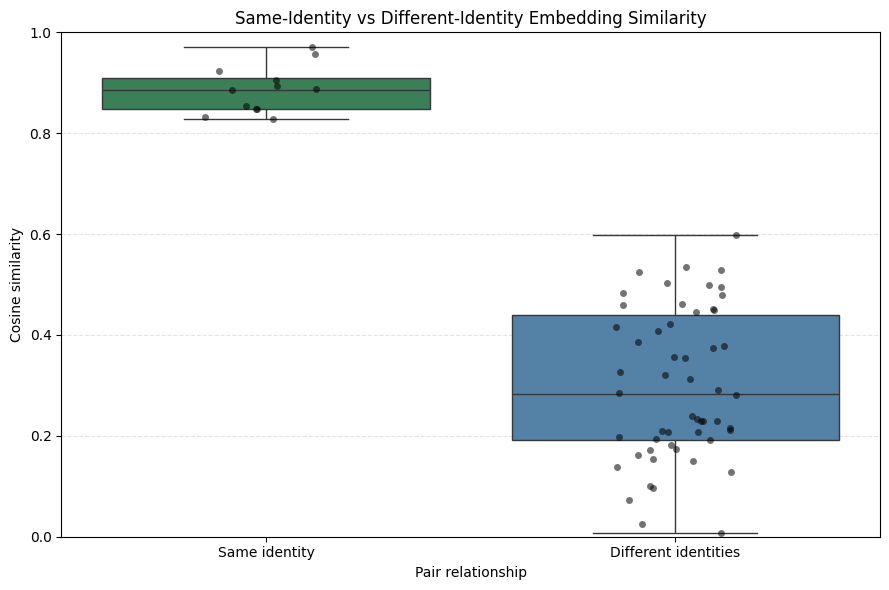

Distribution figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/embedding_similarity_distribution.png


In [27]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=pairwise_similarity,
    x="relationship",
    y="cosine_similarity",
    hue="relationship",
    palette={
        "Same identity": "seagreen",
        "Different identities": "steelblue",
    },
    legend=False,
)

sns.stripplot(
    data=pairwise_similarity,
    x="relationship",
    y="cosine_similarity",
    color="black",
    alpha=0.55,
    jitter=0.15,
)

plt.title(
    "Same-Identity vs Different-Identity Embedding Similarity"
)
plt.xlabel("Pair relationship")
plt.ylabel("Cosine similarity")
plt.ylim(0, 1)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
)
plt.tight_layout()

similarity_distribution_path = (
    figure_directory
    / "embedding_similarity_distribution.png"
)

plt.savefig(
    similarity_distribution_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(
    "Distribution figure saved to:",
    similarity_distribution_path,
)

### Embedding Similarity Findings

The original embeddings showed strong identity separation. Same-identity pairs
had a mean cosine similarity of 0.886, compared with 0.300 for
different-identity pairs.

The lowest same-identity similarity was 0.828, while the highest
different-identity similarity was 0.598. Therefore, no overlap occurred between
the same-identity and different-identity distributions.

The heatmap also showed clear identity-specific blocks. These results indicate
that the FaceNet embeddings contain sufficient information to distinguish the
four authorized members. However, the findings are based on only three original
images per member and should not be interpreted as real-world security
performance.

# Facial Recognition Model Evaluation

The Logistic Regression classifier is evaluated using three-fold
leave-one-expression-out cross-validation.

Each fold holds out one facial expression—neutral, smile, or surprised—
for testing across all four authorized members. The remaining two
expressions and their augmented variants are used for training.

For each fold:

- Eight original images are represented in the training set: two expressions
  for each of the four members.
- All four augmentation variants of each training image are included,
  producing 32 training feature rows.
- The four original images belonging to the held-out expression—one per
  member—are used for testing.
- Augmented versions of test images are excluded from evaluation.

This design prevents augmented variants of a test image from entering the
training set. It also evaluates whether the model can recognize each member
from an unseen facial expression.

Across the three folds, every one of the 12 authorized original images is
evaluated exactly once.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    log_loss,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Use only genuine original images for testing.
original_model_data = (
    image_features[
        image_features["augmentation"] == "original"
    ]
    .copy()
    .reset_index(drop=True)
)

class_labels = sorted(
    image_features["member_id"].unique()
)
class_labels_array = np.array(class_labels)

# Each fold holds out one complete expression.
held_out_expressions = [
    "neutral",
    "smile",
    "surprised",
]

fold_results = []
prediction_records = []
all_true_labels = []
all_predicted_labels = []
all_probabilities = []

for fold_number, test_expression in enumerate(
    held_out_expressions,
    start=1,
):
    # Training includes all variants from the other two expressions.
    train_data = image_features[
        image_features["expression"]
        != test_expression
    ].copy()

    # Testing includes only original images of the held-out expression.
    test_data = original_model_data[
        original_model_data["expression"]
        == test_expression
    ].copy()

    model = Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "classifier",
                LogisticRegression(
                    max_iter=3000,
                    class_weight="balanced",
                    random_state=42,
                ),
            ),
        ]
    )

    model.fit(
        train_data[embedding_columns],
        train_data["member_id"],
    )

    raw_probabilities = model.predict_proba(
        test_data[embedding_columns]
    )

    model_classes = model.named_steps[
        "classifier"
    ].classes_

    # Align probability columns with the shared class-label order.
    aligned_probabilities = np.zeros(
        (
            len(test_data),
            len(class_labels),
        )
    )

    for model_class_index, model_class in enumerate(
        model_classes
    ):
        final_class_index = class_labels.index(
            model_class
        )

        aligned_probabilities[
            :,
            final_class_index,
        ] = raw_probabilities[
            :,
            model_class_index,
        ]

    predicted_labels = class_labels_array[
        np.argmax(
            aligned_probabilities,
            axis=1,
        )
    ]

    true_labels = test_data[
        "member_id"
    ].to_numpy()

    fold_accuracy = accuracy_score(
        true_labels,
        predicted_labels,
    )

    fold_macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        average="macro",
    )

    fold_loss = log_loss(
        true_labels,
        aligned_probabilities,
        labels=class_labels,
    )

    fold_results.append(
        {
            "fold": fold_number,
            "held_out_expression": test_expression,
            "training_source_images": (
                train_data["source_file"].nunique()
            ),
            "training_feature_rows": len(train_data),
            "testing_original_images": len(test_data),
            "accuracy": fold_accuracy,
            "macro_f1": fold_macro_f1,
            "log_loss": fold_loss,
        }
    )

    for row_position, (_, test_row) in enumerate(
        test_data.iterrows()
    ):
        prediction_records.append(
            {
                "fold": fold_number,
                "held_out_expression": test_expression,
                "sample_id": test_row["sample_id"],
                "source_file": test_row["source_file"],
                "true_member": true_labels[row_position],
                "predicted_member": predicted_labels[
                    row_position
                ],
                "confidence": float(
                    aligned_probabilities[
                        row_position
                    ].max()
                ),
                "correct": (
                    true_labels[row_position]
                    == predicted_labels[row_position]
                ),
            }
        )

    all_true_labels.extend(
        true_labels
    )
    all_predicted_labels.extend(
        predicted_labels
    )
    all_probabilities.append(
        aligned_probabilities
    )

cross_validation_results = pd.DataFrame(
    fold_results
)

cross_validation_predictions = pd.DataFrame(
    prediction_records
)

all_probabilities = np.vstack(
    all_probabilities
)

display(cross_validation_results)
display(cross_validation_predictions)

,fold,held_out_expression,training_source_images,training_feature_rows,testing_original_images,accuracy,macro_f1,log_loss
0,1,neutral,8,32,4,1.0,1.0,0.003157
1,2,smile,8,32,4,1.0,1.0,0.001343
2,3,surprised,8,32,4,1.0,1.0,0.012125


,fold,held_out_expression,sample_id,source_file,true_member,predicted_member,confidence,correct
0,1,neutral,member01_neutral_01__original,member01_neutral_01.jpeg,member01,member01,0.999137,True
1,1,neutral,member02_neutral_01__original,member02_neutral_01.jpeg,member02,member02,0.998858,True
2,1,neutral,member03_neutral_01__original,member03_neutral_01.jpeg,member03,member03,0.998812,True
3,1,neutral,member04_neutral_01__original,member04_neutral_01.jpeg,member04,member04,0.990611,True
4,2,smile,member01_smile_01__original,member01_smile_01.jpeg,member01,member01,0.998534,True
5,2,smile,member02_smile_01__original,member02_smile_01.jpeg,member02,member02,0.998676,True
6,2,smile,member03_smile_01__original,member03_smile_01.jpeg,member03,member03,0.998383,True
7,2,smile,member04_smile_01__original,member04_smile_01.jpeg,member04,member04,0.999038,True
8,3,surprised,member01_surprised_01__original,member01_surprised_01.jpeg,member01,member01,0.997219,True
9,3,surprised,member02_surprised_01__original,member02_surprised_01.jpeg,member02,member02,0.992123,True


In [32]:
overall_accuracy = accuracy_score(
    all_true_labels,
    all_predicted_labels,
)

overall_macro_f1 = f1_score(
    all_true_labels,
    all_predicted_labels,
    average="macro",
)

overall_weighted_f1 = f1_score(
    all_true_labels,
    all_predicted_labels,
    average="weighted",
)

overall_log_loss = log_loss(
    all_true_labels,
    all_probabilities,
    labels=class_labels,
)

overall_metrics = pd.DataFrame(
    {
        "metric": [
            "Accuracy",
            "Macro F1-score",
            "Weighted F1-score",
            "Log loss",
        ],
        "value": [
            overall_accuracy,
            overall_macro_f1,
            overall_weighted_f1,
            overall_log_loss,
        ],
    }
)

display(overall_metrics)

classification_report_table = pd.DataFrame(
    classification_report(
        all_true_labels,
        all_predicted_labels,
        labels=class_labels,
        output_dict=True,
        zero_division=0,
    )
).transpose()

display(classification_report_table)

,metric,value
0,Accuracy,1.000000
1,Macro F1-score,1.000000
2,Weighted F1-score,1.000000
3,Log loss,0.005542


,precision,recall,f1-score,support
member01,1.0,1.0,1.0,3.0
member02,1.0,1.0,1.0,3.0
member03,1.0,1.0,1.0,3.0
member04,1.0,1.0,1.0,3.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,12.0
weighted avg,1.0,1.0,1.0,12.0


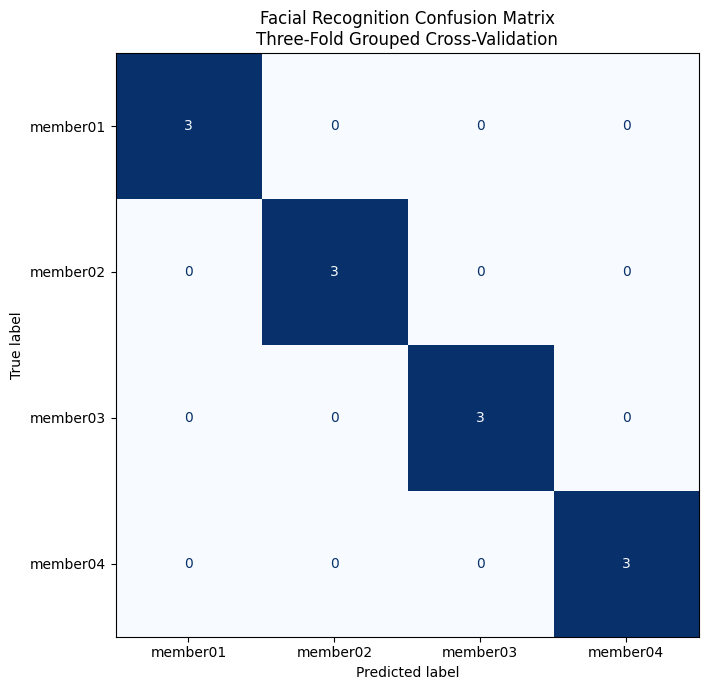

Confusion matrix saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/face_recognition_confusion_matrix.png


In [33]:
fig, axis = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay.from_predictions(
    all_true_labels,
    all_predicted_labels,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Blues",
    colorbar=False,
    ax=axis,
)

axis.set_title(
    "Facial Recognition Confusion Matrix\n"
    "Three-Fold Leave-One-Expression-Out Evaluation"
)
plt.tight_layout()

confusion_matrix_path = (
    figure_directory
    / "face_recognition_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(
    "Confusion matrix saved to:",
    confusion_matrix_path,
)

### Facial Recognition Evaluation Findings

The Logistic Regression facial-recognition model achieved 100% accuracy, a
macro F1-score of 1.00, a weighted F1-score of 1.00, and a log loss of 0.0055.

Each cross-validation fold held out one complete expression across all four
members. Training used the remaining two expressions and their augmentations,
while testing used only the four genuine held-out originals. All 12 test images
were classified correctly.

These results demonstrate strong closed-set recognition for the collected
images. However, the dataset contains only three originals per member, so the
perfect result should not be interpreted as real-world performance. The next
stage evaluates whether the model can reject a person who is not one of the four
authorized identities.

## Unauthorized Validation

The classifier is initially a closed-set model, meaning it will always assign an
input to one of the four authorized identities. An additional similarity
threshold is therefore required to reject unknown people.

The `unauthorized_validation` identity is used to develop this rejection rule.
The separate `unauthorized_test` identity remains untouched until the threshold
has been finalized.

Authorized reference centroids are calculated from original FaceNet embeddings,
while the Logistic Regression classifier is trained on all authorized original
and augmented features.

In [34]:
final_face_classifier = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

final_face_classifier.fit(
    image_features[embedding_columns],
    image_features["member_id"],
)

print("Final authorized classifier trained.")
print(
    "Authorized classes:",
    final_face_classifier.named_steps[
        "classifier"
    ].classes_,
)

Final authorized classifier trained.
Authorized classes: ['member01' 'member02' 'member03' 'member04']


In [35]:
authorized_centroids = {}

for member_id in class_labels:
    member_originals = original_features[
        original_features["member_id"]
        == member_id
    ]

    member_embeddings = member_originals[
        embedding_columns
    ].to_numpy()

    centroid = member_embeddings.mean(axis=0)
    centroid = centroid / np.linalg.norm(centroid)

    authorized_centroids[member_id] = centroid

centroid_table = pd.DataFrame(
    [
        {
            "member_id": member_id,
            "original_images_used": int(
                (
                    original_features["member_id"]
                    == member_id
                ).sum()
            ),
            "centroid_norm": float(
                np.linalg.norm(centroid)
            ),
        }
        for member_id, centroid in
        authorized_centroids.items()
    ]
)

display(centroid_table)

,member_id,original_images_used,centroid_norm
0,member01,3,1.0
1,member02,3,1.0
2,member03,3,1.0
3,member04,3,1.0


In [36]:
validation_folder = (
    IMAGE_ROOT
    / "unauthorized_validation"
)

validation_image_paths = [
    path
    for path in sorted(validation_folder.iterdir())
    if path.is_file()
    and path.suffix.lower() in allowed_extensions
]

if len(validation_image_paths) != 3:
    raise ValueError(
        "Expected exactly three unauthorized-validation images, "
        f"but found {len(validation_image_paths)}."
    )

unauthorized_validation_records = []

for image_path in validation_image_paths:
    with Image.open(image_path) as opened_image:
        validation_image = ImageOps.exif_transpose(
            opened_image
        ).convert("RGB")

    face_batch = face_detector(
        validation_image
    )

    if face_batch is None:
        raise ValueError(
            f"No face detected in {image_path.name}."
        )

    if face_batch.shape[0] != 1:
        raise ValueError(
            f"Expected one face in {image_path.name}, "
            f"but detected {face_batch.shape[0]}."
        )

    with torch.inference_mode():
        validation_embedding_tensor = (
            embedding_model(
                face_batch.to(device)
            )
        )

        validation_embedding_tensor = (
            functional.normalize(
                validation_embedding_tensor,
                p=2,
                dim=1,
            )
        )

    validation_embedding = (
        validation_embedding_tensor[
            0
        ].cpu().numpy()
    )

    validation_feature_row = pd.DataFrame(
        [validation_embedding],
        columns=embedding_columns,
    )

    predicted_member = (
        final_face_classifier.predict(
            validation_feature_row
        )[0]
    )

    predicted_probabilities = (
        final_face_classifier.predict_proba(
            validation_feature_row
        )[0]
    )

    classifier_confidence = float(
        predicted_probabilities.max()
    )

    centroid_similarities = {
        member_id: float(
            validation_embedding
            @ centroid
        )
        for member_id, centroid
        in authorized_centroids.items()
    }

    nearest_centroid_member = max(
        centroid_similarities,
        key=centroid_similarities.get,
    )

    similarity_to_predicted_member = (
        centroid_similarities[
            predicted_member
        ]
    )

    expression = next(
        (
            expression_name
            for expression_name in expressions
            if (
                f"_{expression_name}_"
                in image_path.stem.lower()
            )
        ),
        "unknown",
    )

    unauthorized_validation_records.append(
        {
            "source_file": image_path.name,
            "expression": expression,
            "faces_detected": int(
                face_batch.shape[0]
            ),
            "classifier_prediction": (
                predicted_member
            ),
            "classifier_confidence": (
                classifier_confidence
            ),
            "nearest_centroid": (
                nearest_centroid_member
            ),
            "similarity_to_prediction": (
                similarity_to_predicted_member
            ),
            "maximum_centroid_similarity": max(
                centroid_similarities.values()
            ),
        }
    )

unauthorized_validation_results = pd.DataFrame(
    unauthorized_validation_records
)

display(unauthorized_validation_results)

,source_file,expression,faces_detected,classifier_prediction,classifier_confidence,nearest_centroid,similarity_to_prediction,maximum_centroid_similarity
0,unauthorized_validation_neutral_01.jpeg,neutral,1,member04,0.624593,member04,0.561378,0.561378
1,unauthorized_validation_smile_01.jpeg,smile,1,member04,0.767444,member04,0.488057,0.488057
2,unauthorized_validation_surprised_01.jpeg,surprised,1,member04,0.911049,member04,0.605112,0.605112


### Unauthorized Validation Observations

The closed-set Logistic Regression classifier assigned all three unauthorized
validation images to Member 4 because it was required to choose one of the four
known classes.

Classifier confidence was not sufficient for authentication. One unauthorized
image received confidence above 0.91 despite not belonging to any authorized
member.

In contrast, maximum centroid similarities ranged from approximately 0.488 to
0.605, substantially below the previously observed authorized same-identity
similarities. Therefore, centroid similarity is used as the unknown-person
rejection criterion, while Logistic Regression provides the predicted identity.

In [37]:
authorized_score_records = []

for row_index, row in original_features.iterrows():
    member_id = row["member_id"]
    source_file = row["source_file"]

    current_embedding = row[
        embedding_columns
    ].to_numpy(dtype=float)

    reference_rows = original_features[
        (original_features["member_id"] == member_id)
        & (
            original_features["source_file"]
            != source_file
        )
    ]

    if len(reference_rows) != 2:
        raise ValueError(
            f"Expected two reference originals for {source_file}, "
            f"but found {len(reference_rows)}."
        )

    reference_centroid = reference_rows[
        embedding_columns
    ].to_numpy().mean(axis=0)

    reference_centroid = (
        reference_centroid
        / np.linalg.norm(reference_centroid)
    )

    genuine_similarity = float(
        current_embedding
        @ reference_centroid
    )

    authorized_score_records.append(
        {
            "member_id": member_id,
            "source_file": source_file,
            "expression": row["expression"],
            "similarity_score": genuine_similarity,
            "score_type": "Authorized leave-one-out",
        }
    )

authorized_validation_scores = pd.DataFrame(
    authorized_score_records
)

display(authorized_validation_scores)

display(
    authorized_validation_scores[
        "similarity_score"
    ].describe()
)

,member_id,source_file,expression,similarity_score,score_type
0,member01,member01_neutral_01.jpeg,neutral,0.914835,Authorized leave-one-out
1,member01,member01_smile_01.jpeg,smile,0.939851,Authorized leave-one-out
2,member01,member01_surprised_01.jpeg,surprised,0.887769,Authorized leave-one-out
3,member02,member02_neutral_01.jpeg,neutral,0.964218,Authorized leave-one-out
4,member02,member02_smile_01.jpeg,smile,0.954574,Authorized leave-one-out
5,member02,member02_surprised_01.jpeg,surprised,0.905774,Authorized leave-one-out
6,member03,member03_neutral_01.jpeg,neutral,0.944305,Authorized leave-one-out
7,member03,member03_smile_01.jpeg,smile,0.928664,Authorized leave-one-out
8,member03,member03_surprised_01.jpeg,surprised,0.847625,Authorized leave-one-out
9,member04,member04_neutral_01.jpeg,neutral,0.893982,Authorized leave-one-out


,similarity_score
count,12.000000
mean,0.912727
std,0.035623
min,0.847625
25%,0.892429
50%,0.910376
75%,0.940965
max,0.964218


In [38]:
minimum_authorized_similarity = float(
    authorized_validation_scores[
        "similarity_score"
    ].min()
)

maximum_unauthorized_similarity = float(
    unauthorized_validation_results[
        "similarity_to_prediction"
    ].max()
)

if (
    maximum_unauthorized_similarity
    >= minimum_authorized_similarity
):
    raise ValueError(
        "Authorized and unauthorized validation scores overlap. "
        "A midpoint threshold cannot be selected safely."
    )

face_rejection_threshold = (
    minimum_authorized_similarity
    + maximum_unauthorized_similarity
) / 2

threshold_summary = pd.DataFrame(
    {
        "measurement": [
            "Minimum authorized similarity",
            "Maximum unauthorized-validation similarity",
            "Selected rejection threshold",
            "Separation gap",
        ],
        "value": [
            minimum_authorized_similarity,
            maximum_unauthorized_similarity,
            face_rejection_threshold,
            (
                minimum_authorized_similarity
                - maximum_unauthorized_similarity
            ),
        ],
    }
)

display(threshold_summary)

,measurement,value
0,Minimum authorized similarity,0.847625
1,Maximum unauthorized-validation similarity,0.605112
2,Selected rejection threshold,0.726368
3,Separation gap,0.242512


In [39]:
authorized_threshold_results = (
    authorized_validation_scores.copy()
)

authorized_threshold_results["accepted"] = (
    authorized_threshold_results[
        "similarity_score"
    ]
    >= face_rejection_threshold
)

unauthorized_threshold_results = (
    unauthorized_validation_results.copy()
)

unauthorized_threshold_results[
    "similarity_score"
] = unauthorized_threshold_results[
    "similarity_to_prediction"
]

unauthorized_threshold_results["accepted"] = (
    unauthorized_threshold_results[
        "similarity_score"
    ]
    >= face_rejection_threshold
)

false_rejection_rate = float(
    (
        ~authorized_threshold_results[
            "accepted"
        ]
    ).mean()
)

false_acceptance_rate = float(
    unauthorized_threshold_results[
        "accepted"
    ].mean()
)

threshold_metrics = pd.DataFrame(
    {
        "metric": [
            "False rejection rate",
            "False acceptance rate",
            "Authorized samples evaluated",
            "Unauthorized validation samples evaluated",
        ],
        "value": [
            false_rejection_rate,
            false_acceptance_rate,
            len(authorized_threshold_results),
            len(unauthorized_threshold_results),
        ],
    }
)

display(threshold_metrics)

display(
    unauthorized_threshold_results[
        [
            "source_file",
            "classifier_prediction",
            "classifier_confidence",
            "similarity_score",
            "accepted",
        ]
    ]
)

,metric,value
0,False rejection rate,0.0
1,False acceptance rate,0.0
2,Authorized samples evaluated,12.0
3,Unauthorized validation samples evaluated,3.0


,source_file,classifier_prediction,classifier_confidence,similarity_score,accepted
0,unauthorized_validation_neutral_01.jpeg,member04,0.624593,0.561378,False
1,unauthorized_validation_smile_01.jpeg,member04,0.767444,0.488057,False
2,unauthorized_validation_surprised_01.jpeg,member04,0.911049,0.605112,False


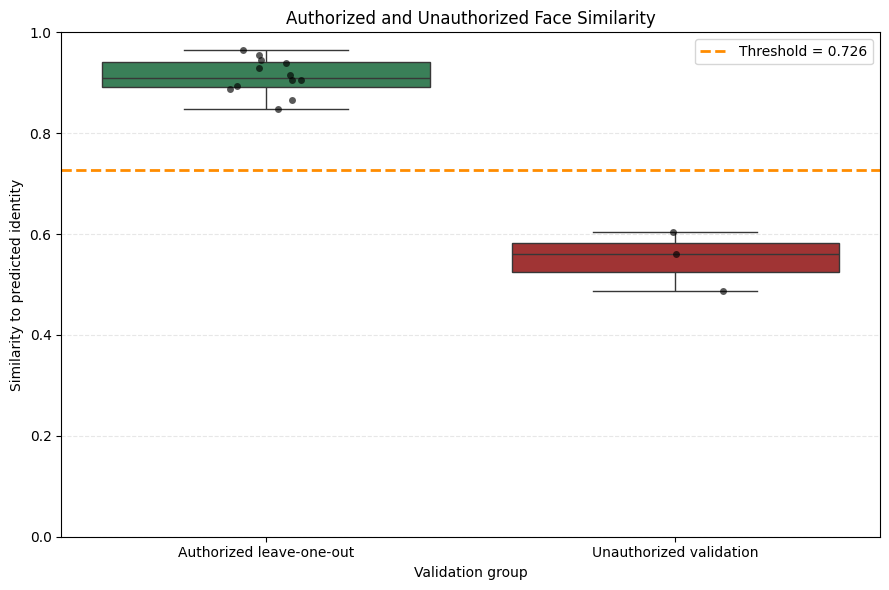

Threshold figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/face_rejection_threshold.png


In [40]:
authorized_plot_data = (
    authorized_threshold_results[
        [
            "similarity_score",
            "score_type",
        ]
    ].copy()
)

unauthorized_plot_data = pd.DataFrame(
    {
        "similarity_score": (
            unauthorized_validation_results[
                "similarity_to_prediction"
            ]
        ),
        "score_type": (
            "Unauthorized validation"
        ),
    }
)

threshold_plot_data = pd.concat(
    [
        authorized_plot_data,
        unauthorized_plot_data,
    ],
    ignore_index=True,
)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=threshold_plot_data,
    x="score_type",
    y="similarity_score",
    hue="score_type",
    palette={
        "Authorized leave-one-out": "seagreen",
        "Unauthorized validation": "firebrick",
    },
    legend=False,
)

sns.stripplot(
    data=threshold_plot_data,
    x="score_type",
    y="similarity_score",
    color="black",
    jitter=0.12,
    alpha=0.65,
)

plt.axhline(
    face_rejection_threshold,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=(
        "Threshold = "
        f"{face_rejection_threshold:.3f}"
    ),
)

plt.title(
    "Authorized and Unauthorized Face Similarity"
)
plt.xlabel("Validation group")
plt.ylabel("Similarity to predicted identity")
plt.ylim(0, 1)
plt.legend()
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)
plt.tight_layout()

threshold_figure_path = (
    figure_directory
    / "face_rejection_threshold.png"
)

plt.savefig(
    threshold_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(
    "Threshold figure saved to:",
    threshold_figure_path,
)

### Rejection Threshold Findings

A facial-similarity rejection threshold of 0.726 was selected using the midpoint
between the lowest authorized leave-one-out similarity and the highest
unauthorized-validation similarity.

The lowest authorized similarity was 0.848, while the highest
unauthorized-validation similarity was 0.605. This produced a separation gap of
0.243.

At the selected threshold, all 12 authorized leave-one-out comparisons were
accepted and all three unauthorized-validation images were rejected. This
produced a validation false rejection rate of 0.00 and a false acceptance rate
of 0.00.

The result also confirms that classifier probability alone is unsuitable for
authentication. One unauthorized image received a classifier confidence of
0.911 but was correctly rejected because its facial similarity was below the
selected threshold.

This threshold should be interpreted as a validation-derived experimental
threshold rather than a production-security threshold. It was calibrated using
authorized leave-one-out scores and images from only one unauthorized validation
identity. A production system would require a larger and more diverse validation
dataset containing additional identities, poses, lighting conditions, cameras,
and image-quality variations.

## Final Held-Out Unauthorized Test

The rejection threshold was fixed at 0.726 using only the authorized
leave-one-out scores and the separate `unauthorized_validation` identity.

The `unauthorized_test` identity and its images were not used for classifier
training, cross-validation, centroid construction, or threshold selection. They
were held out until the rejection threshold had been finalized.

The unauthorized test set is used only to evaluate how the fixed decision rule
behaves on a different unauthorized identity. The threshold is not adjusted
after viewing these test results.

In [41]:
test_folder = IMAGE_ROOT / "unauthorized_test"

test_image_paths = [
    path
    for path in sorted(test_folder.iterdir())
    if path.is_file()
    and path.suffix.lower() in allowed_extensions
]

if len(test_image_paths) != 3:
    raise ValueError(
        "Expected exactly three unauthorized-test images, "
        f"but found {len(test_image_paths)}."
    )

unauthorized_test_records = []

for image_path in test_image_paths:
    with Image.open(image_path) as opened_image:
        test_image = ImageOps.exif_transpose(
            opened_image
        ).convert("RGB")

    face_batch = face_detector(test_image)

    if face_batch is None:
        raise ValueError(
            f"No face detected in {image_path.name}."
        )

    if face_batch.shape[0] != 1:
        raise ValueError(
            f"Expected one face in {image_path.name}, "
            f"but detected {face_batch.shape[0]}."
        )

    with torch.inference_mode():
        test_embedding_tensor = embedding_model(
            face_batch.to(device)
        )

        test_embedding_tensor = functional.normalize(
            test_embedding_tensor,
            p=2,
            dim=1,
        )

    test_embedding = (
        test_embedding_tensor[0]
        .cpu()
        .numpy()
    )

    test_feature_row = pd.DataFrame(
        [test_embedding],
        columns=embedding_columns,
    )

    predicted_member = (
        final_face_classifier.predict(
            test_feature_row
        )[0]
    )

    predicted_probabilities = (
        final_face_classifier.predict_proba(
            test_feature_row
        )[0]
    )

    classifier_confidence = float(
        predicted_probabilities.max()
    )

    centroid_similarities = {
        member_id: float(
            test_embedding @ centroid
        )
        for member_id, centroid
        in authorized_centroids.items()
    }

    nearest_centroid_member = max(
        centroid_similarities,
        key=centroid_similarities.get,
    )

    similarity_to_prediction = (
        centroid_similarities[predicted_member]
    )

    accepted = (
        similarity_to_prediction
        >= face_rejection_threshold
    )

    expression = next(
        (
            expression_name
            for expression_name in expressions
            if (
                f"_{expression_name}_"
                in image_path.stem.lower()
            )
        ),
        "unknown",
    )

    unauthorized_test_records.append(
        {
            "source_file": image_path.name,
            "expression": expression,
            "faces_detected": int(
                face_batch.shape[0]
            ),
            "classifier_prediction": predicted_member,
            "classifier_confidence": (
                classifier_confidence
            ),
            "nearest_centroid": (
                nearest_centroid_member
            ),
            "similarity_to_prediction": (
                similarity_to_prediction
            ),
            "threshold": (
                face_rejection_threshold
            ),
            "accepted": accepted,
            "decision": (
                "AUTHORIZED"
                if accepted
                else "REJECTED"
            ),
        }
    )

unauthorized_test_results = pd.DataFrame(
    unauthorized_test_records
)

display(unauthorized_test_results)

,source_file,expression,faces_detected,classifier_prediction,classifier_confidence,nearest_centroid,similarity_to_prediction,threshold,accepted,decision
0,unauthorized_test_neutral_01.jpeg,neutral,1,member04,0.952452,member04,0.512213,0.726368,False,REJECTED
1,unauthorized_test_smile_01.jpeg,smile,1,member04,0.964677,member04,0.481500,0.726368,False,REJECTED
2,unauthorized_test_surprised_01.jpeg,surprised,1,member04,0.651541,member04,0.390853,0.726368,False,REJECTED


In [42]:
final_test_false_acceptance_rate = float(
    unauthorized_test_results[
        "accepted"
    ].mean()
)

final_test_metrics = pd.DataFrame(
    {
        "metric": [
            "Unauthorized test images",
            "Rejected test images",
            "Accepted test images",
            "Final test false acceptance rate",
            "Fixed rejection threshold",
        ],
        "value": [
            len(unauthorized_test_results),
            int(
                (
                    ~unauthorized_test_results[
                        "accepted"
                    ]
                ).sum()
            ),
            int(
                unauthorized_test_results[
                    "accepted"
                ].sum()
            ),
            final_test_false_acceptance_rate,
            face_rejection_threshold,
        ],
    }
)

display(final_test_metrics)

metrics_directory = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
)
metrics_directory.mkdir(
    parents=True,
    exist_ok=True,
)

unauthorized_test_results_path = (
    metrics_directory
    / "unauthorized_face_test_results.csv"
)

unauthorized_test_results.to_csv(
    unauthorized_test_results_path,
    index=False,
)

print(
    "Test results saved to:",
    unauthorized_test_results_path,
)

,metric,value
0,Unauthorized test images,3.000000
1,Rejected test images,3.000000
2,Accepted test images,0.000000
3,Final test false acceptance rate,0.000000
4,Fixed rejection threshold,0.726368


Test results saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/metrics/unauthorized_face_test_results.csv


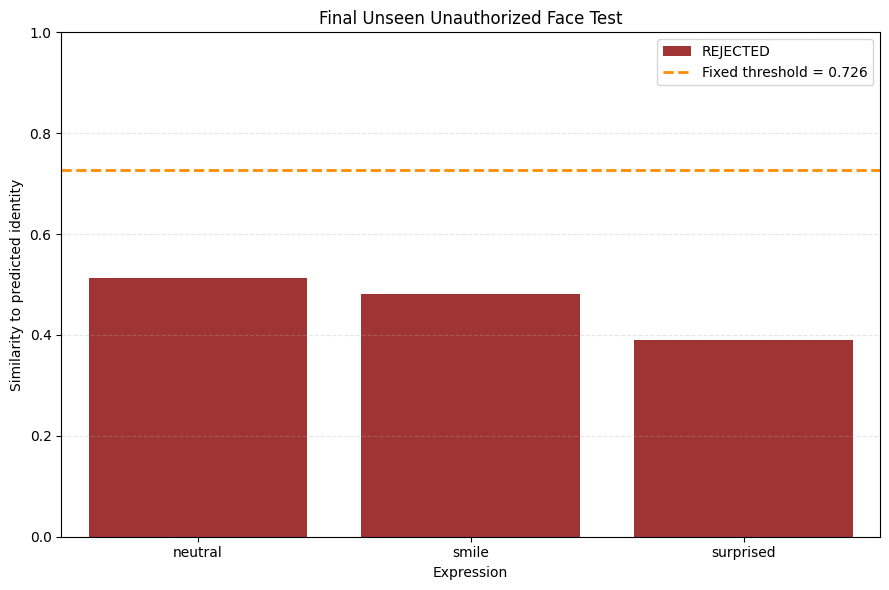

Final test figure saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/figures/unauthorized_face_final_test.png


In [43]:
plt.figure(figsize=(9, 6))

test_plot = sns.barplot(
    data=unauthorized_test_results,
    x="expression",
    y="similarity_to_prediction",
    hue="decision",
    palette={
        "AUTHORIZED": "seagreen",
        "REJECTED": "firebrick",
    },
)

plt.axhline(
    face_rejection_threshold,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=(
        "Fixed threshold = "
        f"{face_rejection_threshold:.3f}"
    ),
)

plt.title(
    "Final Unseen Unauthorized Face Test"
)
plt.xlabel("Expression")
plt.ylabel("Similarity to predicted identity")
plt.ylim(0, 1)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

handles, labels = test_plot.get_legend_handles_labels()
unique_legend = dict(zip(labels, handles))

plt.legend(
    unique_legend.values(),
    unique_legend.keys(),
)
plt.tight_layout()

final_test_figure_path = (
    figure_directory
    / "unauthorized_face_final_test.png"
)

plt.savefig(
    final_test_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(
    "Final test figure saved to:",
    final_test_figure_path,
)

### Final Unauthorized Test Findings

All three images from the final unseen unauthorized identity were correctly
rejected using the fixed similarity threshold of 0.726.

The test similarity scores ranged from approximately 0.391 to 0.512, remaining
well below the rejection threshold. This produced a final test false acceptance
rate of 0.00.

The closed-set classifier assigned the unknown person to Member 4 and produced
confidence above 0.95 for two images. However, the similarity check correctly
rejected them. This confirms that classifier probability alone cannot be treated
as authentication confidence.

These findings are encouraging but limited. The final unauthorized evaluation
contains only one external identity and three images, so it does not establish
real-world security performance.

In [46]:
import joblib

models_directory = PROJECT_ROOT / "models"
models_directory.mkdir(
    parents=True,
    exist_ok=True,
)

face_model_bundle = {
    "classifier": final_face_classifier,
    "authorized_centroids": authorized_centroids,
    "rejection_threshold": float(
        face_rejection_threshold
    ),
    "embedding_columns": list(
        embedding_columns
    ),
    "class_labels": list(
        class_labels
    ),
    "embedding_model": (
        "facenet-pytorch InceptionResnetV1 "
        "pretrained on VGGFace2"
    ),
    "face_detector": "MTCNN",
    "aligned_image_size": 160,
    "evaluation_method": (
        "Three-fold leave-one-expression-out"
    ),
    "decision_rule": (
        "Use Logistic Regression to predict the identity. "
        "Accept the prediction only when the cosine similarity "
        "between the face embedding and the predicted identity "
        "centroid is greater than or equal to the fixed "
        "rejection threshold."
    ),
}

face_model_path = (
    models_directory
    / "face_recognition_bundle.joblib"
)

joblib.dump(
    face_model_bundle,
    face_model_path,
)

print("Model bundle saved to:", face_model_path)
print(
    "Saved rejection threshold:",
    face_model_bundle["rejection_threshold"],
)

Model bundle saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/models/face_recognition_bundle.joblib


In [47]:
metrics_directory = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
)
metrics_directory.mkdir(
    parents=True,
    exist_ok=True,
)

face_metrics = {
    "cross_validation": {
        "folds": int(
            len(cross_validation_results)
        ),
        "evaluation_method": (
            "Three-fold leave-one-expression-out"
        ),
        "accuracy": float(
            overall_accuracy
        ),
        "macro_f1": float(
            overall_macro_f1
        ),
        "weighted_f1": float(
            overall_weighted_f1
        ),
        "log_loss": float(
            overall_log_loss
        ),
        "authorized_originals_evaluated": int(
            len(all_true_labels)
        ),
    },
    "threshold_validation": {
        "minimum_authorized_similarity": float(
            minimum_authorized_similarity
        ),
        "maximum_unauthorized_similarity": float(
            maximum_unauthorized_similarity
        ),
        "rejection_threshold": float(
            face_rejection_threshold
        ),
        "separation_gap": float(
            minimum_authorized_similarity
            - maximum_unauthorized_similarity
        ),
        "false_rejection_rate": float(
            false_rejection_rate
        ),
        "false_acceptance_rate": float(
            false_acceptance_rate
        ),
        "authorized_samples": int(
            len(authorized_threshold_results)
        ),
        "unauthorized_samples": int(
            len(unauthorized_threshold_results)
        ),
    },
    "final_unauthorized_test": {
        "unauthorized_identity_count": 1,
        "images_evaluated": int(
            len(unauthorized_test_results)
        ),
        "images_rejected": int(
            (
                ~unauthorized_test_results[
                    "accepted"
                ]
            ).sum()
        ),
        "images_accepted": int(
            unauthorized_test_results[
                "accepted"
            ].sum()
        ),
        "false_acceptance_rate": float(
            final_test_false_acceptance_rate
        ),
    },
    "limitations": [
        (
            "Only three original images were "
            "available per member."
        ),
        (
            "Only one identity was used for "
            "validation rejection testing."
        ),
        (
            "Only one different identity was used "
            "for final unauthorized testing."
        ),
        (
            "Results do not represent production "
            "security performance."
        ),
    ],
}

face_metrics_path = (
    metrics_directory
    / "face_model_metrics.json"
)

with open(
    face_metrics_path,
    "w",
    encoding="utf-8",
) as metrics_file:
    json.dump(
        face_metrics,
        metrics_file,
        indent=2,
    )

print("Metrics saved to:", face_metrics_path)

Metrics saved to: /content/drive/MyDrive/formative-2-machine-learning-pipeline/outputs/metrics/face_model_metrics.json
